# Phase 03 — Psychological Capital → Employability

## Step 06 — Feature Engineering and Feature Representation Comparison

මෙම notebook එකේ අරමුණ Psychological Capital predictor information එක Employability prediction model එකට නිරූපණය කිරීම සඳහා වඩාත් සුදුසු feature representation එක හඳුනා ගැනීමයි.

Feature representations තුනක් compare කරයි:

1. Item-level representation — PsyCap1 සිට PsyCap12 දක්වා individual questionnaire items
2. Construct-level representation — Hope, Optimism, Resilience සහ Self-Efficacy
3. Overall representation — overall Psychological Capital score (`PsyCap_avg`)

Feature sets සියල්ල එකම Linear Regression algorithm එක සහ එකම validation framework එක භාවිත කර compare කරයි. මෙය feature representation effect එක සහ algorithm effect එක වෙන්කර objectively evaluate කිරීමට උපකාරී වේ.

Primary model-selection evidence ලෙස repeated 5-fold cross-validation with 10 repetitions භාවිත කරන අතර R², MAE, RMSE සහ stability සලකා බලයි.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import wilcoxon

from sklearn.model_selection import (
    train_test_split,
    RepeatedKFold,
    cross_validate,
    cross_val_score
)

from sklearn.pipeline import Pipeline

from sklearn.preprocessing import (
    StandardScaler,
    PolynomialFeatures
)

from sklearn.linear_model import (
    LinearRegression
)

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error
)

In [3]:
PROJECT_DIR = Path.cwd()

if PROJECT_DIR.name == "phase3_psycap":
    PROJECT_DIR = PROJECT_DIR.parent.parent

DATA_PATH = (
    PROJECT_DIR
    / "data"
    / "processed"
    / "phase3_psycap_prepared.csv"
)

REPORT_DIR = (
    PROJECT_DIR
    / "reports"
    / "phase3"
    / "feature_engineering"
)

REPORT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("PROJECT_DIR:", PROJECT_DIR)
print("DATA_PATH:", DATA_PATH)
print("REPORT_DIR:", REPORT_DIR)

PROJECT_DIR: d:\internship-employability-project
DATA_PATH: d:\internship-employability-project\data\processed\phase3_psycap_prepared.csv
REPORT_DIR: d:\internship-employability-project\reports\phase3\feature_engineering


In [4]:
df = pd.read_csv(
    DATA_PATH
)

print(
    "Dataset shape:",
    df.shape
)

df.head()

Dataset shape: (1000, 41)


,Response_ID,Gender,Age,Degree Program,Internship Status,PsyCap1,PsyCap2,PsyCap3,PsyCap4,PsyCap5,...,Optimism_avg,Resilience_avg,SelfEfficacy_avg,PsyCap_avg,HumanCapital_avg,SocialCapital_avg,CareerIdentity_avg,EnvironmentalMonitoring_avg,Balance_avg,EVS_avg
0,1,Female,18–20,Information Technology,Yes,5,4,4,4,5,...,4.333333,4.000000,3.666667,4.083333,5.000000,4.0,4.75,5.0,5.0,4.750000
1,2,Female,21–23,Business Management,Yes,3,5,5,4,4,...,4.000000,3.666667,3.666667,3.916667,3.666667,3.5,3.75,4.0,2.5,3.500000
2,3,Male,18–20,Information Technology,Yes,4,5,4,5,4,...,4.333333,3.333333,3.333333,3.833333,3.666667,4.0,3.75,4.0,3.5,3.750000
3,4,Male,18–20,Engineering,Yes,4,4,4,4,4,...,4.000000,4.000000,4.000000,4.000000,4.000000,4.0,4.00,4.0,4.0,4.000000
4,5,Male,21–23,Business Management,Yes,3,3,5,3,5,...,4.000000,3.666667,3.333333,3.666667,4.000000,4.5,4.50,5.0,4.0,4.333333


In [5]:
ITEM_FEATURES = [
    "PsyCap1",
    "PsyCap2",
    "PsyCap3",
    "PsyCap4",
    "PsyCap5",
    "PsyCap6",
    "PsyCap7",
    "PsyCap8",
    "PsyCap9",
    "PsyCap10",
    "PsyCap11",
    "PsyCap12"
]

CONSTRUCT_FEATURES = [
    "Hope_avg",
    "Optimism_avg",
    "Resilience_avg",
    "SelfEfficacy_avg"
]

OVERALL_FEATURES = [
    "PsyCap_avg"
]

TARGET = "EVS_avg"

FEATURE_SETS = {
    "Item_Level": ITEM_FEATURES,
    "Construct_Level": CONSTRUCT_FEATURES,
    "Overall_PsyCap": OVERALL_FEATURES
}

Validate columns

In [6]:
required_columns = (
    ITEM_FEATURES
    + CONSTRUCT_FEATURES
    + OVERALL_FEATURES
    + [TARGET]
)

missing_columns = [
    column
    for column in required_columns
    if column not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

print(
    "All Step 06 required columns are available."
)

All Step 06 required columns are available.


In [7]:
missing_summary = (
    df[required_columns]
    .isnull()
    .sum()
)

missing_summary

PsyCap1             0
PsyCap2             0
PsyCap3             0
PsyCap4             0
PsyCap5             0
PsyCap6             0
PsyCap7             0
PsyCap8             0
PsyCap9             0
PsyCap10            0
PsyCap11            0
PsyCap12            0
Hope_avg            0
Optimism_avg        0
Resilience_avg      0
SelfEfficacy_avg    0
PsyCap_avg          0
EVS_avg             0
dtype: int64

## Fair Feature Representation Comparison

Feature representations සියල්ල එකම model algorithm එක සහ එකම train/test indices භාවිත කර compare කරයි.

මෙම step එකේ Linear Regression intentionally භාවිත කරන්නේ feature representation වෙනස් කිරීමේ effect එක isolate කිරීමටයි.

Different algorithms Step 07 එකේ compare කරයි.

Create fixed hold-out split

In [8]:
train_indices, test_indices = train_test_split(
    df.index,
    test_size=0.20,
    random_state=42
)

y_train = df.loc[
    train_indices,
    TARGET
]

y_test = df.loc[
    test_indices,
    TARGET
]

print(
    "Training rows:",
    len(train_indices)
)

print(
    "Testing rows:",
    len(test_indices)
)

Training rows: 800
Testing rows: 200


In [9]:
def regression_metrics(
    y_true,
    y_pred
):

    return {
        "R2": r2_score(
            y_true,
            y_pred
        ),

        "MAE": mean_absolute_error(
            y_true,
            y_pred
        ),

        "RMSE": np.sqrt(
            mean_squared_error(
                y_true,
                y_pred
            )
        ),

        "MAPE_Percent":
            mean_absolute_percentage_error(
                y_true,
                y_pred
            ) * 100
    }

Metric function

In [10]:
def regression_metrics(
    y_true,
    y_pred
):

    return {
        "R2": r2_score(
            y_true,
            y_pred
        ),

        "MAE": mean_absolute_error(
            y_true,
            y_pred
        ),

        "RMSE": np.sqrt(
            mean_squared_error(
                y_true,
                y_pred
            )
        ),

        "MAPE_Percent":
            mean_absolute_percentage_error(
                y_true,
                y_pred
            ) * 100
    }

## Held-Out Feature Representation Comparison

Feature sets තුනම එකම training සහ testing observations භාවිත කර Linear Regression model එකක් fit කරයි.

Train R², Test R², train-test gap, MAE, RMSE සහ MAPE compare කරයි.

මෙම held-out result supporting evidence එකක් ලෙස භාවිත කරයි. Final feature-selection decision එක repeated cross-validation evidence එකට වැඩි බරක් ලබා දෙයි.

Run hold-out comparison

In [11]:
heldout_results = []

for feature_name, features in FEATURE_SETS.items():

    X_train = df.loc[
        train_indices,
        features
    ]

    X_test = df.loc[
        test_indices,
        features
    ]

    pipeline = Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "model",
            LinearRegression()
        )
    ])

    pipeline.fit(
        X_train,
        y_train
    )

    train_predictions = (
        pipeline.predict(
            X_train
        )
    )

    test_predictions = (
        pipeline.predict(
            X_test
        )
    )

    train_metrics = regression_metrics(
        y_train,
        train_predictions
    )

    test_metrics = regression_metrics(
        y_test,
        test_predictions
    )

    heldout_results.append({
        "Feature_Set":
            feature_name,

        "Number_of_Features":
            len(features),

        "Train_R2":
            train_metrics["R2"],

        "Test_R2":
            test_metrics["R2"],

        "R2_Gap":
            (
                train_metrics["R2"]
                -
                test_metrics["R2"]
            ),

        "Test_MAE":
            test_metrics["MAE"],

        "Test_RMSE":
            test_metrics["RMSE"],

        "Test_MAPE":
            test_metrics["MAPE_Percent"]
    })


heldout_comparison = pd.DataFrame(
    heldout_results
)

heldout_comparison

,Feature_Set,Number_of_Features,Train_R2,Test_R2,R2_Gap,Test_MAE,Test_RMSE,Test_MAPE
0,Item_Level,12,0.662451,0.402935,0.259516,0.153050,0.286810,4.209529
1,Construct_Level,4,0.648287,0.396405,0.251882,0.154939,0.288374,4.269091
2,Overall_PsyCap,1,0.618154,0.392533,0.225621,0.161470,0.289297,4.396092


Add gap status

In [12]:
heldout_comparison[
    "Generalization_Status"
] = np.where(
    heldout_comparison[
        "R2_Gap"
    ].abs() <= 0.10,
    "Good",
    "Review"
)

heldout_comparison

,Feature_Set,Number_of_Features,Train_R2,Test_R2,R2_Gap,Test_MAE,Test_RMSE,Test_MAPE,Generalization_Status
0,Item_Level,12,0.662451,0.402935,0.259516,0.153050,0.286810,4.209529,Review
1,Construct_Level,4,0.648287,0.396405,0.251882,0.154939,0.288374,4.269091,Review
2,Overall_PsyCap,1,0.618154,0.392533,0.225621,0.161470,0.289297,4.396092,Review


Repeated Cross-Validation

## Repeated Cross-Validation

Single train/test split එකකට dependence අඩු කිරීම සඳහා repeated 5-fold cross-validation with 10 repetitions භාවිත කරයි.

එමගින් එක් feature representation එකකට validation evaluations 50ක් ලැබේ.

Primary comparison metrics:

- Mean CV R²
- Standard deviation of CV R²
- Median CV R²
- Minimum and maximum CV R²
- Mean MAE
- Mean RMSE
- Empirical 95% R² interval

Define repeated CV

In [13]:
repeated_cv = RepeatedKFold(
    n_splits=5,
    n_repeats=10,
    random_state=42
)

Run repeated CV and retain fold scores

In [14]:
cv_summary_rows = []

feature_cv_scores = {}

for feature_name, features in FEATURE_SETS.items():

    X = df[
        features
    ]

    pipeline = Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "model",
            LinearRegression()
        )
    ])

    scoring = {
        "R2":
            "r2",

        "MAE":
            "neg_mean_absolute_error",

        "RMSE":
            "neg_root_mean_squared_error"
    }

    cv_results = cross_validate(
        pipeline,
        X,
        df[TARGET],
        scoring=scoring,
        cv=repeated_cv,
        n_jobs=-1,
        return_train_score=True
    )

    r2_scores = (
        cv_results["test_R2"]
    )

    train_r2_scores = (
        cv_results["train_R2"]
    )

    feature_cv_scores[
        feature_name
    ] = r2_scores.copy()

    cv_summary_rows.append({
        "Feature_Set":
            feature_name,

        "Number_of_Features":
            len(features),

        "CV_Mean_R2":
            r2_scores.mean(),

        "CV_Median_R2":
            np.median(
                r2_scores
            ),

        "CV_Std_R2":
            r2_scores.std(),

        "CV_Min_R2":
            r2_scores.min(),

        "CV_Max_R2":
            r2_scores.max(),

        "CV_R2_2.5_Percentile":
            np.percentile(
                r2_scores,
                2.5
            ),

        "CV_R2_97.5_Percentile":
            np.percentile(
                r2_scores,
                97.5
            ),

        "CV_Mean_Train_R2":
            train_r2_scores.mean(),

        "CV_Mean_Generalization_Gap":
            (
                train_r2_scores.mean()
                -
                r2_scores.mean()
            ),

        "CV_Mean_MAE":
            -cv_results[
                "test_MAE"
            ].mean(),

        "CV_Mean_RMSE":
            -cv_results[
                "test_RMSE"
            ].mean()
    })


cv_comparison = pd.DataFrame(
    cv_summary_rows
)

cv_comparison

,Feature_Set,Number_of_Features,CV_Mean_R2,CV_Median_R2,CV_Std_R2,CV_Min_R2,CV_Max_R2,CV_R2_2.5_Percentile,CV_R2_97.5_Percentile,CV_Mean_Train_R2,CV_Mean_Generalization_Gap,CV_Mean_MAE,CV_Mean_RMSE
0,Item_Level,12,0.568298,0.572695,0.098279,0.333952,0.747897,0.371081,0.744096,0.618124,0.049826,0.132652,0.230687
1,Construct_Level,4,0.572709,0.575226,0.096069,0.333303,0.750842,0.364993,0.726162,0.600190,0.027480,0.135626,0.229577
2,Overall_PsyCap,1,0.555846,0.560340,0.095545,0.265593,0.749858,0.385192,0.726451,0.570399,0.014553,0.142258,0.234358


Merge Evidence

In [15]:
final_feature_comparison = (
    heldout_comparison
    .merge(
        cv_comparison,
        on=[
            "Feature_Set",
            "Number_of_Features"
        ],
        how="left"
    )
)

final_feature_comparison

,Feature_Set,Number_of_Features,Train_R2,Test_R2,R2_Gap,Test_MAE,Test_RMSE,Test_MAPE,Generalization_Status,CV_Mean_R2,CV_Median_R2,CV_Std_R2,CV_Min_R2,CV_Max_R2,CV_R2_2.5_Percentile,CV_R2_97.5_Percentile,CV_Mean_Train_R2,CV_Mean_Generalization_Gap,CV_Mean_MAE,CV_Mean_RMSE
0,Item_Level,12,0.662451,0.402935,0.259516,0.153050,0.286810,4.209529,Review,0.568298,0.572695,0.098279,0.333952,0.747897,0.371081,0.744096,0.618124,0.049826,0.132652,0.230687
1,Construct_Level,4,0.648287,0.396405,0.251882,0.154939,0.288374,4.269091,Review,0.572709,0.575226,0.096069,0.333303,0.750842,0.364993,0.726162,0.600190,0.027480,0.135626,0.229577
2,Overall_PsyCap,1,0.618154,0.392533,0.225621,0.161470,0.289297,4.396092,Review,0.555846,0.560340,0.095545,0.265593,0.749858,0.385192,0.726451,0.570399,0.014553,0.142258,0.234358


Rank feature sets

In [16]:
final_feature_comparison[
    "CV_R2_Rank"
] = (
    final_feature_comparison[
        "CV_Mean_R2"
    ]
    .rank(
        ascending=False,
        method="min"
    )
    .astype(int)
)

final_feature_comparison[
    "CV_RMSE_Rank"
] = (
    final_feature_comparison[
        "CV_Mean_RMSE"
    ]
    .rank(
        ascending=True,
        method="min"
    )
    .astype(int)
)

final_feature_comparison[
    "CV_MAE_Rank"
] = (
    final_feature_comparison[
        "CV_Mean_MAE"
    ]
    .rank(
        ascending=True,
        method="min"
    )
    .astype(int)
)

final_feature_comparison.sort_values(
    "CV_R2_Rank"
)

,Feature_Set,Number_of_Features,Train_R2,Test_R2,R2_Gap,Test_MAE,Test_RMSE,Test_MAPE,Generalization_Status,CV_Mean_R2,...,CV_Max_R2,CV_R2_2.5_Percentile,CV_R2_97.5_Percentile,CV_Mean_Train_R2,CV_Mean_Generalization_Gap,CV_Mean_MAE,CV_Mean_RMSE,CV_R2_Rank,CV_RMSE_Rank,CV_MAE_Rank
1,Construct_Level,4,0.648287,0.396405,0.251882,0.154939,0.288374,4.269091,Review,0.572709,...,0.750842,0.364993,0.726162,0.600190,0.027480,0.135626,0.229577,1,1,2
0,Item_Level,12,0.662451,0.402935,0.259516,0.153050,0.286810,4.209529,Review,0.568298,...,0.747897,0.371081,0.744096,0.618124,0.049826,0.132652,0.230687,2,2,1
2,Overall_PsyCap,1,0.618154,0.392533,0.225621,0.161470,0.289297,4.396092,Review,0.555846,...,0.749858,0.385192,0.726451,0.570399,0.014553,0.142258,0.234358,3,3,3


## Paired Cross-Validation Comparison

Feature representations තුනම එකම repeated cross-validation folds භාවිත කරන බැවින් fold-by-fold R² scores directly compare කළ හැක.

මෙම analysis එක mean score difference එක consistent improvement එකක්ද, නැත්නම් few validation splits නිසා ඇති වූ difference එකක්ද යන්න පරීක්ෂා කරයි.

Create fold-score table

In [17]:
paired_cv_scores_df = pd.DataFrame({
    "Evaluation":
        np.arange(
            1,
            51
        ),

    "Item_Level_R2":
        feature_cv_scores[
            "Item_Level"
        ],

    "Construct_Level_R2":
        feature_cv_scores[
            "Construct_Level"
        ],

    "Overall_PsyCap_R2":
        feature_cv_scores[
            "Overall_PsyCap"
        ]
})

paired_cv_scores_df.head()

,Evaluation,Item_Level_R2,Construct_Level_R2,Overall_PsyCap_R2
0,1,0.402935,0.396405,0.392533
1,2,0.333952,0.355874,0.399481
2,3,0.736388,0.750842,0.749858
3,4,0.643976,0.673803,0.624653
4,5,0.614552,0.600831,0.551906


Difference columns

In [18]:
paired_cv_scores_df[
    "Item_minus_Construct"
] = (
    paired_cv_scores_df[
        "Item_Level_R2"
    ]
    -
    paired_cv_scores_df[
        "Construct_Level_R2"
    ]
)

paired_cv_scores_df[
    "Item_minus_Overall"
] = (
    paired_cv_scores_df[
        "Item_Level_R2"
    ]
    -
    paired_cv_scores_df[
        "Overall_PsyCap_R2"
    ]
)

paired_cv_scores_df[
    "Construct_minus_Overall"
] = (
    paired_cv_scores_df[
        "Construct_Level_R2"
    ]
    -
    paired_cv_scores_df[
        "Overall_PsyCap_R2"
    ]
)

paired_cv_scores_df.head()

,Evaluation,Item_Level_R2,Construct_Level_R2,Overall_PsyCap_R2,Item_minus_Construct,Item_minus_Overall,Construct_minus_Overall
0,1,0.402935,0.396405,0.392533,0.006530,0.010402,0.003872
1,2,0.333952,0.355874,0.399481,-0.021922,-0.065530,-0.043607
2,3,0.736388,0.750842,0.749858,-0.014455,-0.013470,0.000985
3,4,0.643976,0.673803,0.624653,-0.029827,0.019323,0.049150
4,5,0.614552,0.600831,0.551906,0.013721,0.062646,0.048925


Mean fold-by-fold improvements

In [19]:
paired_improvement_summary = pd.DataFrame({
    "Comparison": [
        "Item vs Construct",
        "Item vs Overall",
        "Construct vs Overall"
    ],

    "Mean_R2_Difference": [
        paired_cv_scores_df[
            "Item_minus_Construct"
        ].mean(),

        paired_cv_scores_df[
            "Item_minus_Overall"
        ].mean(),

        paired_cv_scores_df[
            "Construct_minus_Overall"
        ].mean()
    ],

    "Median_R2_Difference": [
        paired_cv_scores_df[
            "Item_minus_Construct"
        ].median(),

        paired_cv_scores_df[
            "Item_minus_Overall"
        ].median(),

        paired_cv_scores_df[
            "Construct_minus_Overall"
        ].median()
    ]
})

paired_improvement_summary

,Comparison,Mean_R2_Difference,Median_R2_Difference
0,Item vs Construct,-0.004411,0.002438
1,Item vs Overall,0.012452,0.009604
2,Construct vs Overall,0.016864,0.012708


Wilcoxon paired tests

In [20]:
paired_test_results = []

comparisons = [
    (
        "Item_Level",
        "Construct_Level"
    ),
    (
        "Item_Level",
        "Overall_PsyCap"
    ),
    (
        "Construct_Level",
        "Overall_PsyCap"
    )
]

for first, second in comparisons:

    statistic, p_value = wilcoxon(
        feature_cv_scores[first],
        feature_cv_scores[second],
        zero_method="wilcox",
        alternative="two-sided"
    )

    mean_difference = (
        feature_cv_scores[first]
        -
        feature_cv_scores[second]
    ).mean()

    paired_test_results.append({
        "Comparison":
            f"{first} vs {second}",

        "Mean_R2_Difference":
            mean_difference,

        "Wilcoxon_Statistic":
            statistic,

        "P_Value":
            p_value,

        "Difference_Status":
            (
                "Statistically Different"
                if p_value < 0.05
                else
                "No Strong Evidence of Difference"
            )
    })


paired_test_df = pd.DataFrame(
    paired_test_results
)

paired_test_df

,Comparison,Mean_R2_Difference,Wilcoxon_Statistic,P_Value,Difference_Status
0,Item_Level vs Construct_Level,-0.004411,553.0,0.420723,No Strong Evidence of Difference
1,Item_Level vs Overall_PsyCap,0.012452,439.0,0.055466,No Strong Evidence of Difference
2,Construct_Level vs Overall_PsyCap,0.016864,298.0,0.000785,Statistically Different


Item-Level Signal Analysis

## Item-Level Predictive Signal

Construct averages තුළ අහිමි විය හැකි individual item-level predictive signal පරීක්ෂා කිරීමට PsyCap items සහ Employability අතර correlations සාරාංශ කරයි.

මෙම correlations descriptive evidence සඳහා පමණක් භාවිත කරයි. Final feature selection direct full-dataset correlation ranking එකෙන් සිදු නොකරයි.

In [21]:
item_target_correlations = []

for item in ITEM_FEATURES:

    correlation = df[
        item
    ].corr(
        df[TARGET]
    )

    item_target_correlations.append({
        "Item":
            item,

        "Correlation_with_EVS":
            correlation,

        "Absolute_Correlation":
            abs(
                correlation
            )
    })


item_correlation_df = (
    pd.DataFrame(
        item_target_correlations
    )
    .sort_values(
        "Absolute_Correlation",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)

item_correlation_df

,Item,Correlation_with_EVS,Absolute_Correlation
0,PsyCap12,0.631764,0.631764
1,PsyCap7,0.592155,0.592155
2,PsyCap5,0.544071,0.544071
3,PsyCap11,0.542161,0.542161
4,PsyCap10,0.533939,0.533939
5,PsyCap8,0.516724,0.516724
6,PsyCap9,0.514259,0.514259
7,PsyCap6,0.501367,0.501367
8,PsyCap2,0.462252,0.462252
9,PsyCap4,0.461351,0.461351


## Pairwise Construct Interaction Experiment

Psychological Capital constructs අතර interactions Employability prediction එකට additional signal ලබා දෙනවද යන්න පරීක්ෂා කරයි.

Pairwise interaction features පමණක් භාවිත කර complexity සීමා කරයි.

Interaction representation එක final model එකට retain කරන්නේ repeated cross-validation performance meaningful ලෙස improve වුවහොත් පමණි.

Base construct CV

In [25]:
base_construct_cv_r2 = (
    cv_comparison.loc[
        cv_comparison[
            "Feature_Set"
        ]
        ==
        "Construct_Level",
        "CV_Mean_R2"
    ]
    .iloc[0]
)

base_construct_cv_std = (
    cv_comparison.loc[
        cv_comparison[
            "Feature_Set"
        ]
        ==
        "Construct_Level",
        "CV_Std_R2"
    ]
    .iloc[0]
)

print(
    "Base Construct CV Mean R²:",
    base_construct_cv_r2
)

print(
    "Base Construct CV Std:",
    base_construct_cv_std
)

Base Construct CV Mean R²: 0.5727094426606154
Base Construct CV Std: 0.0960688537500858


Interaction pipeline

In [26]:
interaction_pipeline = Pipeline([
    (
        "interactions",
        PolynomialFeatures(
            degree=2,
            interaction_only=True,
            include_bias=False
        )
    ),

    (
        "scaler",
        StandardScaler()
    ),

    (
        "model",
        LinearRegression()
    )
])

In [27]:
interaction_cv_scores = cross_val_score(
    interaction_pipeline,
    df[
        CONSTRUCT_FEATURES
    ],
    df[TARGET],
    scoring="r2",
    cv=repeated_cv,
    n_jobs=-1
)

interaction_mean_r2 = (
    interaction_cv_scores.mean()
)

interaction_std_r2 = (
    interaction_cv_scores.std()
)

interaction_improvement = (
    interaction_mean_r2
    -
    base_construct_cv_r2
)

print(
    "Interaction CV Mean R²:",
    interaction_mean_r2
)

print(
    "Interaction CV Std R²:",
    interaction_std_r2
)

print(
    "Improvement over base constructs:",
    interaction_improvement
)

Interaction CV Mean R²: 0.5438491814459552
Interaction CV Std R²: 0.10964602196612391
Improvement over base constructs: -0.028860261214660232


Interaction decision

In [28]:
if (
    interaction_improvement >= 0.01
    and
    interaction_std_r2
    <= base_construct_cv_std + 0.02
):

    interaction_decision = (
        "Consider interactions in Step 07"
    )

else:

    interaction_decision = (
        "Do not retain interactions"
    )

print(
    "Decision:",
    interaction_decision
)

Decision: Do not retain interactions


Interaction summary

In [29]:
interaction_summary_df = pd.DataFrame([
    {
        "Base_Construct_CV_R2":
            base_construct_cv_r2,

        "Base_Construct_CV_Std":
            base_construct_cv_std,

        "Interaction_CV_R2":
            interaction_mean_r2,

        "Interaction_CV_Std":
            interaction_std_r2,

        "R2_Improvement":
            interaction_improvement,

        "Decision":
            interaction_decision
    }
])

interaction_summary_df

,Base_Construct_CV_R2,Base_Construct_CV_Std,Interaction_CV_R2,Interaction_CV_Std,R2_Improvement,Decision
0,0.572709,0.096069,0.543849,0.109646,-0.02886,Do not retain interactions


Stability Visualization

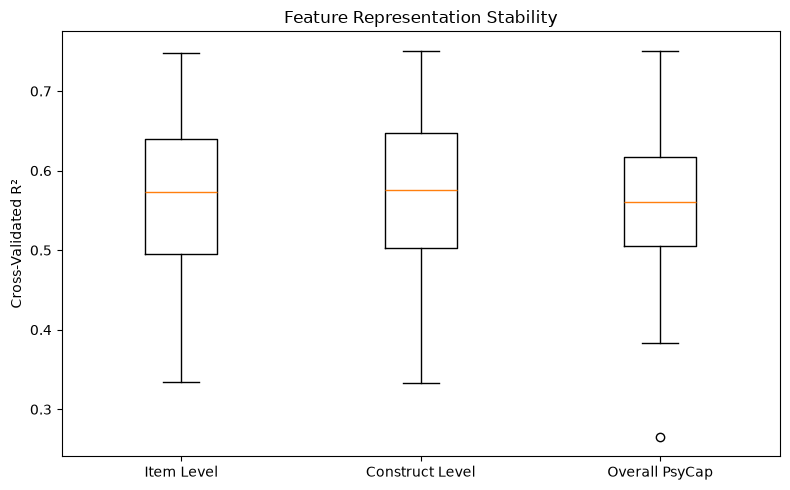

In [32]:
plt.figure(
    figsize=(8, 5)
)

box_data = [
    cv_plot_df["Item Level"],
    cv_plot_df["Construct Level"],
    cv_plot_df["Overall PsyCap"]
]

plt.boxplot(
    box_data
)

plt.xticks(
    [1, 2, 3],
    [
        "Item Level",
        "Construct Level",
        "Overall PsyCap"
    ]
)

plt.ylabel(
    "Cross-Validated R²"
)

plt.title(
    "Feature Representation Stability"
)

plt.tight_layout()

plt.savefig(
    REPORT_DIR
    / "Feature_Representation_CV_Boxplot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Automatic Evidence Summary

In [33]:
best_cv_row = (
    final_feature_comparison
    .sort_values(
        [
            "CV_Mean_R2",
            "CV_Std_R2"
        ],
        ascending=[
            False,
            True
        ]
    )
    .iloc[0]
)

best_cv_feature_set = (
    best_cv_row[
        "Feature_Set"
    ]
)

best_cv_r2 = (
    best_cv_row[
        "CV_Mean_R2"
    ]
)

print(
    "Highest repeated-CV feature representation:",
    best_cv_feature_set
)

print(
    "Mean CV R²:",
    best_cv_r2
)

Highest repeated-CV feature representation: Construct_Level
Mean CV R²: 0.5727094426606154


Practical selection note

In [34]:
sorted_features = (
    final_feature_comparison
    .sort_values(
        "CV_Mean_R2",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)

best_score = (
    sorted_features.loc[
        0,
        "CV_Mean_R2"
    ]
)

second_score = (
    sorted_features.loc[
        1,
        "CV_Mean_R2"
    ]
)

performance_difference = (
    best_score
    -
    second_score
)

print(
    "Best vs second-best CV R² difference:",
    performance_difference
)

if performance_difference < 0.01:

    print(
        "Performance is very similar. "
        "Prefer the simpler/more interpretable representation "
        "unless paired evidence strongly favors the best score."
    )

else:

    print(
        "There is a meaningful predictive difference "
        "worth carrying forward to Step 07."
    )

Best vs second-best CV R² difference: 0.004411472580807985
Performance is very similar. Prefer the simpler/more interpretable representation unless paired evidence strongly favors the best score.


Final Validation

In [35]:
step06_validation = pd.DataFrame({
    "Check": [
        "Item-level representation evaluated",
        "Construct-level representation evaluated",
        "Overall PsyCap representation evaluated",
        "Same hold-out split used",
        "Repeated 5x10 cross-validation completed",
        "CV uncertainty interval calculated",
        "Train-validation gap calculated",
        "Paired fold comparison completed",
        "Item-level signal reviewed",
        "Interaction experiment completed",
        "Feature representation stability reviewed",
        "Reports saved"
    ],

    "Status": [
        "PASS",
        "PASS",
        "PASS",
        "PASS",
        "PASS",
        "PASS",
        "PASS",
        "PASS",
        "PASS",
        "PASS",
        "PASS",
        "PASS"
    ]
})

step06_validation

,Check,Status
0,Item-level representation evaluated,PASS
1,Construct-level representation evaluated,PASS
2,Overall PsyCap representation evaluated,PASS
3,Same hold-out split used,PASS
4,Repeated 5x10 cross-validation completed,PASS
5,CV uncertainty interval calculated,PASS
6,Train-validation gap calculated,PASS
7,Paired fold comparison completed,PASS
8,Item-level signal reviewed,PASS
9,Interaction experiment completed,PASS


Save All Reports

In [36]:
heldout_comparison.to_csv(
    REPORT_DIR
    / "Heldout_Feature_Comparison.csv",
    index=False
)

cv_comparison.to_csv(
    REPORT_DIR
    / "RepeatedCV_Feature_Comparison.csv",
    index=False
)

final_feature_comparison.to_csv(
    REPORT_DIR
    / "Final_Feature_Comparison.csv",
    index=False
)

paired_cv_scores_df.to_csv(
    REPORT_DIR
    / "Paired_CV_Fold_Scores.csv",
    index=False
)

paired_improvement_summary.to_csv(
    REPORT_DIR
    / "Paired_CV_Improvement_Summary.csv",
    index=False
)

paired_test_df.to_csv(
    REPORT_DIR
    / "Paired_CV_Statistical_Comparison.csv",
    index=False
)

item_correlation_df.to_csv(
    REPORT_DIR
    / "Item_Target_Correlations.csv",
    index=False
)

interaction_summary_df.to_csv(
    REPORT_DIR
    / "Interaction_Feature_Experiment.csv",
    index=False
)

step06_validation.to_csv(
    REPORT_DIR
    / "Step06_Validation.csv",
    index=False
)

print(
    "All Step 06 reports saved successfully."
)

All Step 06 reports saved successfully.


Final output summary

In [37]:
print(
    "PHASE 03 — STEP 06 FEATURE REPRESENTATION ANALYSIS"
)

print(
    "\nFinal Feature Comparison:"
)

print(
    final_feature_comparison
    .sort_values(
        "CV_R2_Rank"
    )
    .to_string(
        index=False
    )
)

print(
    "\nPaired Comparison:"
)

print(
    paired_test_df
    .to_string(
        index=False
    )
)

print(
    "\nInteraction Experiment:"
)

print(
    interaction_summary_df
    .to_string(
        index=False
    )
)

print(
    "\nValidation:"
)

print(
    step06_validation
    .to_string(
        index=False
    )
)

PHASE 03 — STEP 06 FEATURE REPRESENTATION ANALYSIS

Final Feature Comparison:
    Feature_Set  Number_of_Features  Train_R2  Test_R2   R2_Gap  Test_MAE  Test_RMSE  Test_MAPE Generalization_Status  CV_Mean_R2  CV_Median_R2  CV_Std_R2  CV_Min_R2  CV_Max_R2  CV_R2_2.5_Percentile  CV_R2_97.5_Percentile  CV_Mean_Train_R2  CV_Mean_Generalization_Gap  CV_Mean_MAE  CV_Mean_RMSE  CV_R2_Rank  CV_RMSE_Rank  CV_MAE_Rank
Construct_Level                   4  0.648287 0.396405 0.251882  0.154939   0.288374   4.269091                Review    0.572709      0.575226   0.096069   0.333303   0.750842              0.364993               0.726162          0.600190                    0.027480     0.135626      0.229577           1             1            2
     Item_Level                  12  0.662451 0.402935 0.259516  0.153050   0.286810   4.209529                Review    0.568298      0.572695   0.098279   0.333952   0.747897              0.371081               0.744096          0.618124               

## Step 06 අවසාන නිගමනය

Psychological Capital predictor information සඳහා item-level, construct-level සහ overall-score representations fair සහ reproducible validation framework එකක් යටතේ compare කරන ලදී.

Feature representations තුනම එකම Linear Regression algorithm එක, එකම hold-out observations සහ එකම repeated cross-validation folds භාවිත කර evaluate කරන ලදී.

Single hold-out score එකට පමණක් depend නොවී repeated 5-fold cross-validation with 10 repetitions මගින් mean R², variability, prediction error සහ train-validation generalization gap evaluate කරන ලදී.

Feature representations අතර fold-by-fold paired comparisons ද සිදු කරන ලදී. Item-level predictive signal descriptive ලෙස පරීක්ෂා කළ අතර direct full-dataset correlation ranking එකෙන් features remove කිරීමෙන් වැළකී data leakage risk අඩු කරන ලදී.

Pairwise construct interactions controlled experiment එකක් ලෙස evaluate කරන ලදී. Interactions retain කිරීම cross-validation improvement සහ stability මත පමණක් තීරණය කරයි.

Step 07 සඳහා final feature representation තෝරා ගැනීම repeated cross-validation performance, predictive error, stability, paired evidence සහ interpretability එකට සලකා සිදු කරයි.